---

# Data Science Competition FIK FAIR 2026

*Predicting an Anonymous Competition Score from 24 transformed environmental and climate features.*

---

## Team Name

- Name 1 (Role)
- Name 2
- Name 3

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Preprocessing Verification**](#4)
5. [**Modelling**](#5)
6. [**Ensemble and Error Analysis**](#6)
7. [**Submission**](#7)


---

# Introduction <a name="1"></a>

---

## Overview

*FIK FAIR 2026 hosts a tabular regression competition in which each record is described by 24 anonymised numerical features derived from environmental and climate indicators. The organisers passed the raw indicators through rank normalisation, a bounded transformation, a private linear projection, standardisation, controlled perturbation and rounding, so the features carry no physical unit and no known meaning.*

*The target is the Anonymous Competition Score, a constructed composite whose formula is private. With only 382 labelled rows, the main risks are overfitting, optimistic validation and chasing a public leaderboard that is computed on roughly 29 rows.*

## Aim

*The notebook aims to minimise the RMSE of the predicted score on the private leaderboard. Every preprocessing idea is treated as a hypothesis and kept only when repeated cross-validation confirms it, and the final predictor is a cross-validated blend of kernel models, gradient boosting and pretrained tabular foundation models.*

## Metric

***Root Mean Squared Error (RMSE)** measures the typical size of the prediction error in target units, with large errors penalised quadratically. It is the primary ranking metric, and MAE is used as the tie-breaker.*

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}$$

*Because the loss is quadratic, the few records with a score above 70 dominate the error budget, so the analysis pays special attention to the right tail of the target.*

## Dataset

*Data sourced from Kaggle at: https://www.kaggle.com/competitions/data-science-competition-fikfair2026*

*The dataset contains 478 records, split into 382 training rows with a target and 96 test rows without one. There are no missing values and every feature is stored with six decimals.*

*The dataset is used to learn a mapping from the anonymised features to the Anonymous Competition Score.*

**Attributes**

1.  `record_id`                  : Anonymous technical identifier with no geographic or source meaning
2.  `feature_01` to `feature_24` : Transformed, dimensionless environmental and climate features

**Target**
 `target`       : Anonymous Competition Score, a continuous value between about 32.6 and 100.4

## Approach: Verified Preprocessing and a Stacked Blend

*The approach combines models that see the data in different ways. Kernel models (SVR, kNN) work on a 12-component PCA view of the features with a log-shifted target, gradient boosting works on the raw features, and the pretrained foundation models TabICLv2 and TabPFN v2 predict through in-context learning without any gradient training on the competition data.*

*All models share the same repeated 5-fold split, and the blend weights are fitted with non-negative least squares on out-of-fold predictions, with a nested split to estimate the blend error honestly.*

```
24 raw features
    |
    +-- StandardScaler -> PCA(12) -> SVR / kNN   (target: log(y - 30))
    +-- raw features  -> CatBoost / ExtraTrees  (target: y)
    +-- raw features  -> TabICLv2 / TabPFN v2   (pretrained, in-context)
         |
    NNLS blend on out-of-fold predictions -> prediction
```

*The split is plain repeated K-fold because the test rows are no closer to the training rows than the training rows are to each other, which the neighbour analysis in Section 3 verifies.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

The notebook targets a Kaggle session with two T4 GPUs and internet access enabled, which is needed to install the foundation model packages and download their open checkpoints from Hugging Face. Recorded runtime: the full notebook takes about 8 minutes on a laptop CPU, and the foundation models run considerably faster on the following GPUs.

In [1]:
!nvidia-smi

Mon Sep 28 14:55:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q tabicl tabpfn catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 827.5/827.5 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 26.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [3]:
import os
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy import stats
from scipy.optimize import nnls
from scipy.sparse.csgraph import connected_components
from statsmodels.nonparametric.smoothers_lowess import lowess

from catboost import CatBoostRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA, FastICA
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (GroupKFold, KFold, RepeatedKFold,
                                     StratifiedKFold, cross_val_predict)
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.svm import SVR
from tabicl import TabICLRegressor
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

warnings.filterwarnings('ignore')

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

## Settings

All paths, hyperparameters, and environment flags are centralised here. Switching between Kaggle and local execution requires no changes outside this class.

In [5]:
class Settings:
    SEED       = 42
    _ON_KAGGLE = Path('/kaggle/input').exists()

    DATA_DIR   = (
        next(Path('/kaggle/input').rglob('train.csv')).parent
        if _ON_KAGGLE else Path('../data')
    )
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('../outputs')
    FIG_DIR    = OUTPUT_DIR / 'fikfair_dsc2026'

    N_SPLITS   = 5
    N_REPEATS  = 3
    PCA_DIM    = 12
    LOG_SHIFT  = 30.0
    DEVICES    = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
print('data:', CFG.DATA_DIR, '| devices:', CFG.DEVICES)

data: /kaggle/input/competitions/data-science-competition-fikfair2026 | devices: ['cuda:0', 'cuda:1']


## Load Dataset

Load the three competition files and the list of feature columns. No visualisation here.

In [6]:
train = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test  = pd.read_csv(CFG.DATA_DIR / 'test.csv')
template = pd.read_csv(CFG.DATA_DIR / 'submission_template.csv')

FEATURES = [c for c in train.columns if c.startswith('feature_')]
X, y  = train[FEATURES].values, train['target'].values
X_te  = test[FEATURES].values
X_all = np.vstack([X, X_te])

print(f'Train: {train.shape}  Test: {test.shape}  Template: {template.shape}  Features: {len(FEATURES)}')

Train: (382, 26)  Test: (96, 25)  Template: (96, 2)  Features: 24


---

# Exploratory Data Analysis <a name="3"></a>

---

The analysis moves from data integrity to the target, then to feature structure, the shape of the feature-target relationship, train-test shift, and finally the neighbourhood structure that decides the validation design. Each step ends with the decision it drives.

## Integrity and Duplicates

Missing values, duplicated rows, rounding precision and the `record_id` pattern are checked first, since any of them could make cross-validation leak information.

In [7]:
tr_id = train['record_id'].str[1:].astype(int)
te_id = test['record_id'].str[1:].astype(int)

print('missing (train/test)       :', int(train.isna().sum().sum()), int(test.isna().sum().sum()))
print('duplicate feature rows      :', train.duplicated(FEATURES).sum(), test.duplicated(FEATURES).sum())
print('train-test identical rows   :', len(train[FEATURES].merge(test[FEATURES], how='inner')))
print('unique values per feature   :', train[FEATURES].nunique().min(), 'to', train[FEATURES].nunique().max())
print('ids cover 1..478 exactly    :', sorted(set(tr_id) | set(te_id)) == list(range(1, 479)))
print('spearman(record_id, target) : %.3f (p=%.2f)' % stats.spearmanr(tr_id, y))

missing (train/test)       : 0 0
duplicate feature rows      : 0 0
train-test identical rows   : 0
unique values per feature   : 382 to 382
ids cover 1..478 exactly    : True
spearman(record_id, target) : 0.049 (p=0.34)


#### Insights

> The data is clean. There are no missing values and no exact duplicates inside or across splits, and every feature has as many unique values as rows, so the rounding step did not create ties.

> The `record_id` values form one shuffled sequence from D0001 to D0478 and have no rank correlation with the target, which matches the rule that the identifier carries no information. It is therefore excluded from modelling.

## Target Distribution

Because RMSE squares each error, the shape of the target, especially its right tail, decides which rows dominate the score.

count    382.000
mean      51.204
std       12.906
min       32.586
25%       39.689
50%       50.256
75%       60.166
max      100.440
skew=0.748  excess kurtosis=0.511  shapiro p=2.34e-11
predict-the-mean RMSE = 12.889


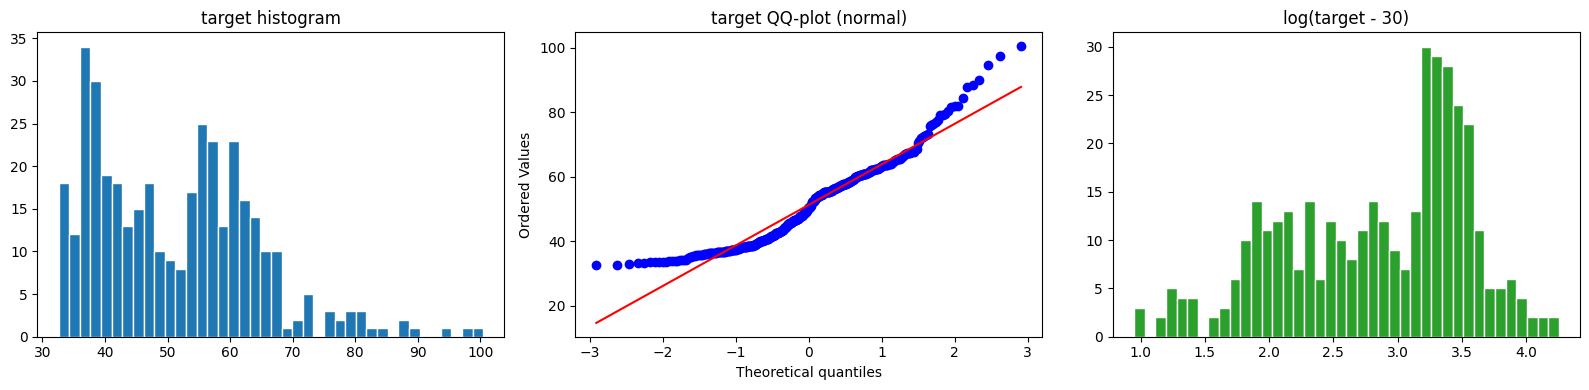

In [8]:
print(pd.Series(y).describe().round(3).to_string())
print(f'skew={stats.skew(y):.3f}  excess kurtosis={stats.kurtosis(y):.3f}  '
      f'shapiro p={stats.shapiro(y).pvalue:.2e}')
print(f'predict-the-mean RMSE = {y.std():.3f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(y, bins=40, edgecolor='w')
ax[0].set_title('target histogram')
stats.probplot(y, plot=ax[1])
ax[1].set_title('target QQ-plot (normal)')
ax[2].hist(np.log(y - CFG.LOG_SHIFT), bins=40, edgecolor='w', color='tab:green')
ax[2].set_title('log(target - 30)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'target.png')
plt.show()

#### Insights

> The target is bimodal, with one mode around 37 and another around 57, plus a thin right tail that reaches 100. It has a hard floor near 32.6, which suggests the score is clipped or rescaled from below.

> The shifted log transform `log(y - 30)` pulls the tail in and spreads the dense lower mode. Section 4 tests whether this helps, because a transform that looks better on a histogram can still hurt a model in RMSE terms.

## Feature Correlation and Latent Dimension

The features are described as a private linear projection of a smaller set of indicators. If that is true, the correlation matrix should be strongly structured and the PCA spectrum should show a few dominant directions.

top correlations with target:
feature_09    0.391
feature_15   -0.376
feature_12   -0.372
feature_17    0.352
feature_13    0.348
feature_07   -0.332
feature_03   -0.259
feature_23    0.248

PCA explained variance % (first 8): [40.39 25.9  14.03 11.03  2.4   1.67  1.43  0.9 ]
eigenvalues above the Marchenko-Pastur noise edge (1.50): 4
condition number: 3397


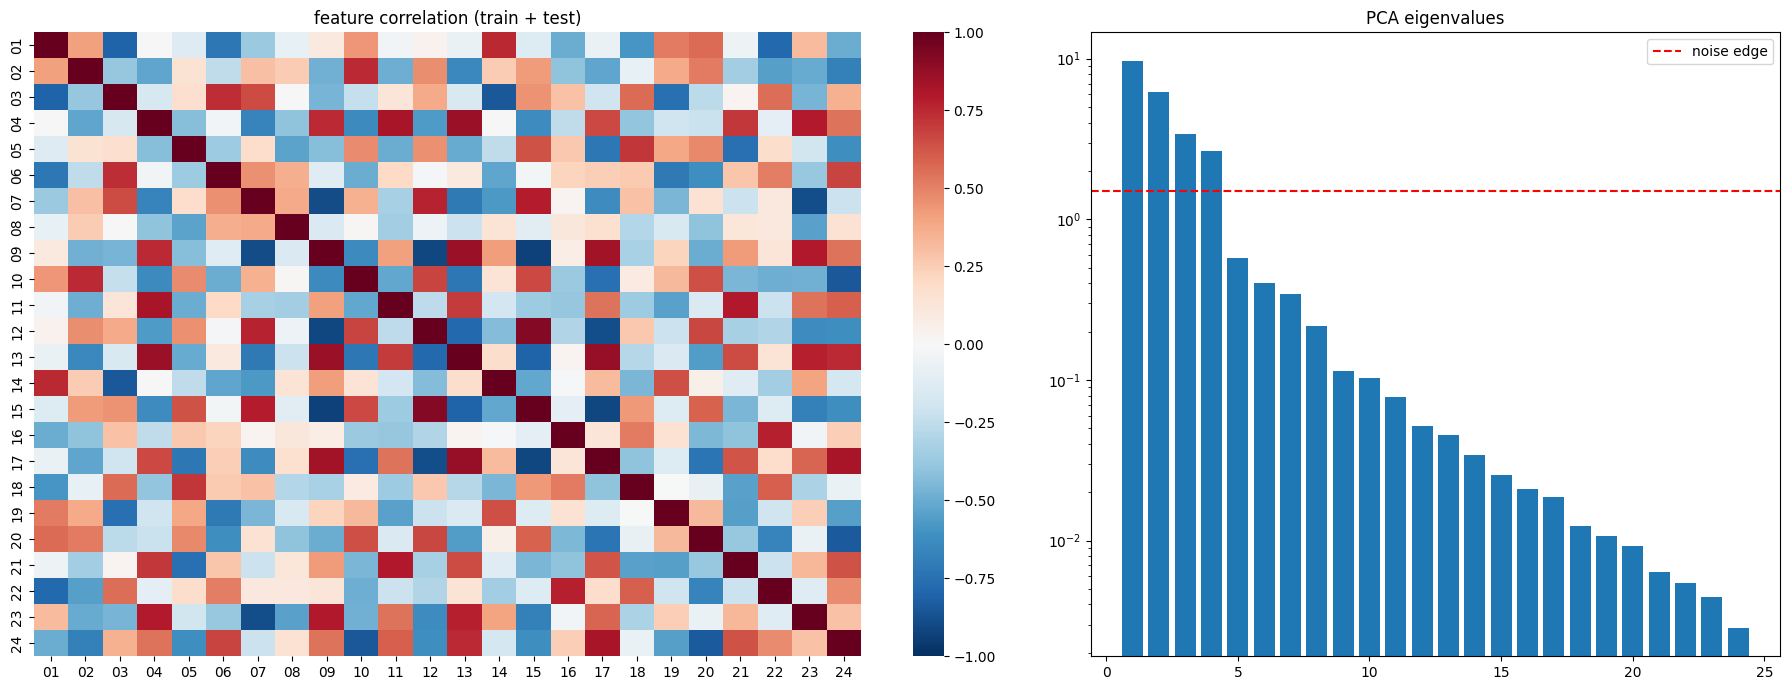

In [9]:
sc_all = StandardScaler().fit(X_all)
Z_all  = sc_all.transform(X_all)
corr   = pd.DataFrame(X_all, columns=FEATURES).corr()
t_corr = train[FEATURES].corrwith(train['target']).sort_values(key=abs, ascending=False)
print('top correlations with target:')
print(t_corr.head(8).round(3).to_string())

ev = np.linalg.eigvalsh(np.cov(Z_all.T))[::-1]
mp_edge = (1 + np.sqrt(len(FEATURES) / len(X_all))) ** 2
print('\nPCA explained variance % (first 8):', np.round(100 * ev[:8] / ev.sum(), 2))
print(f'eigenvalues above the Marchenko-Pastur noise edge ({mp_edge:.2f}): {(ev > mp_edge).sum()}')
print(f'condition number: {ev[0] / ev[-1]:.0f}')

fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[0],
            xticklabels=[c[-2:] for c in FEATURES], yticklabels=[c[-2:] for c in FEATURES])
ax[0].set_title('feature correlation (train + test)')
ax[1].bar(range(1, 25), ev)
ax[1].axhline(mp_edge, ls='--', c='r', label='noise edge')
ax[1].set_yscale('log')
ax[1].set_title('PCA eigenvalues')
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'correlation_pca.png')
plt.show()

#### Insights

> The features are highly collinear. The average absolute pairwise correlation is about 0.41, 44 pairs exceed 0.7 and the strongest pair reaches 0.94. The first four principal components hold 91% of the variance and are the only ones above the random-noise edge, which confirms the low-dimensional projection described by the organisers.

> The strongest single feature explains only about 15% of the target variance. The target signal is therefore spread across many directions, including low-variance components that PCA would treat as noise, so aggressive dimension reduction is risky and must be verified.

## Shape of the Feature-Target Relationship

A LOWESS curve per feature shows whether the dependence is monotone, and a comparison of a linear model against additive splines quantifies how much non-linearity there is.

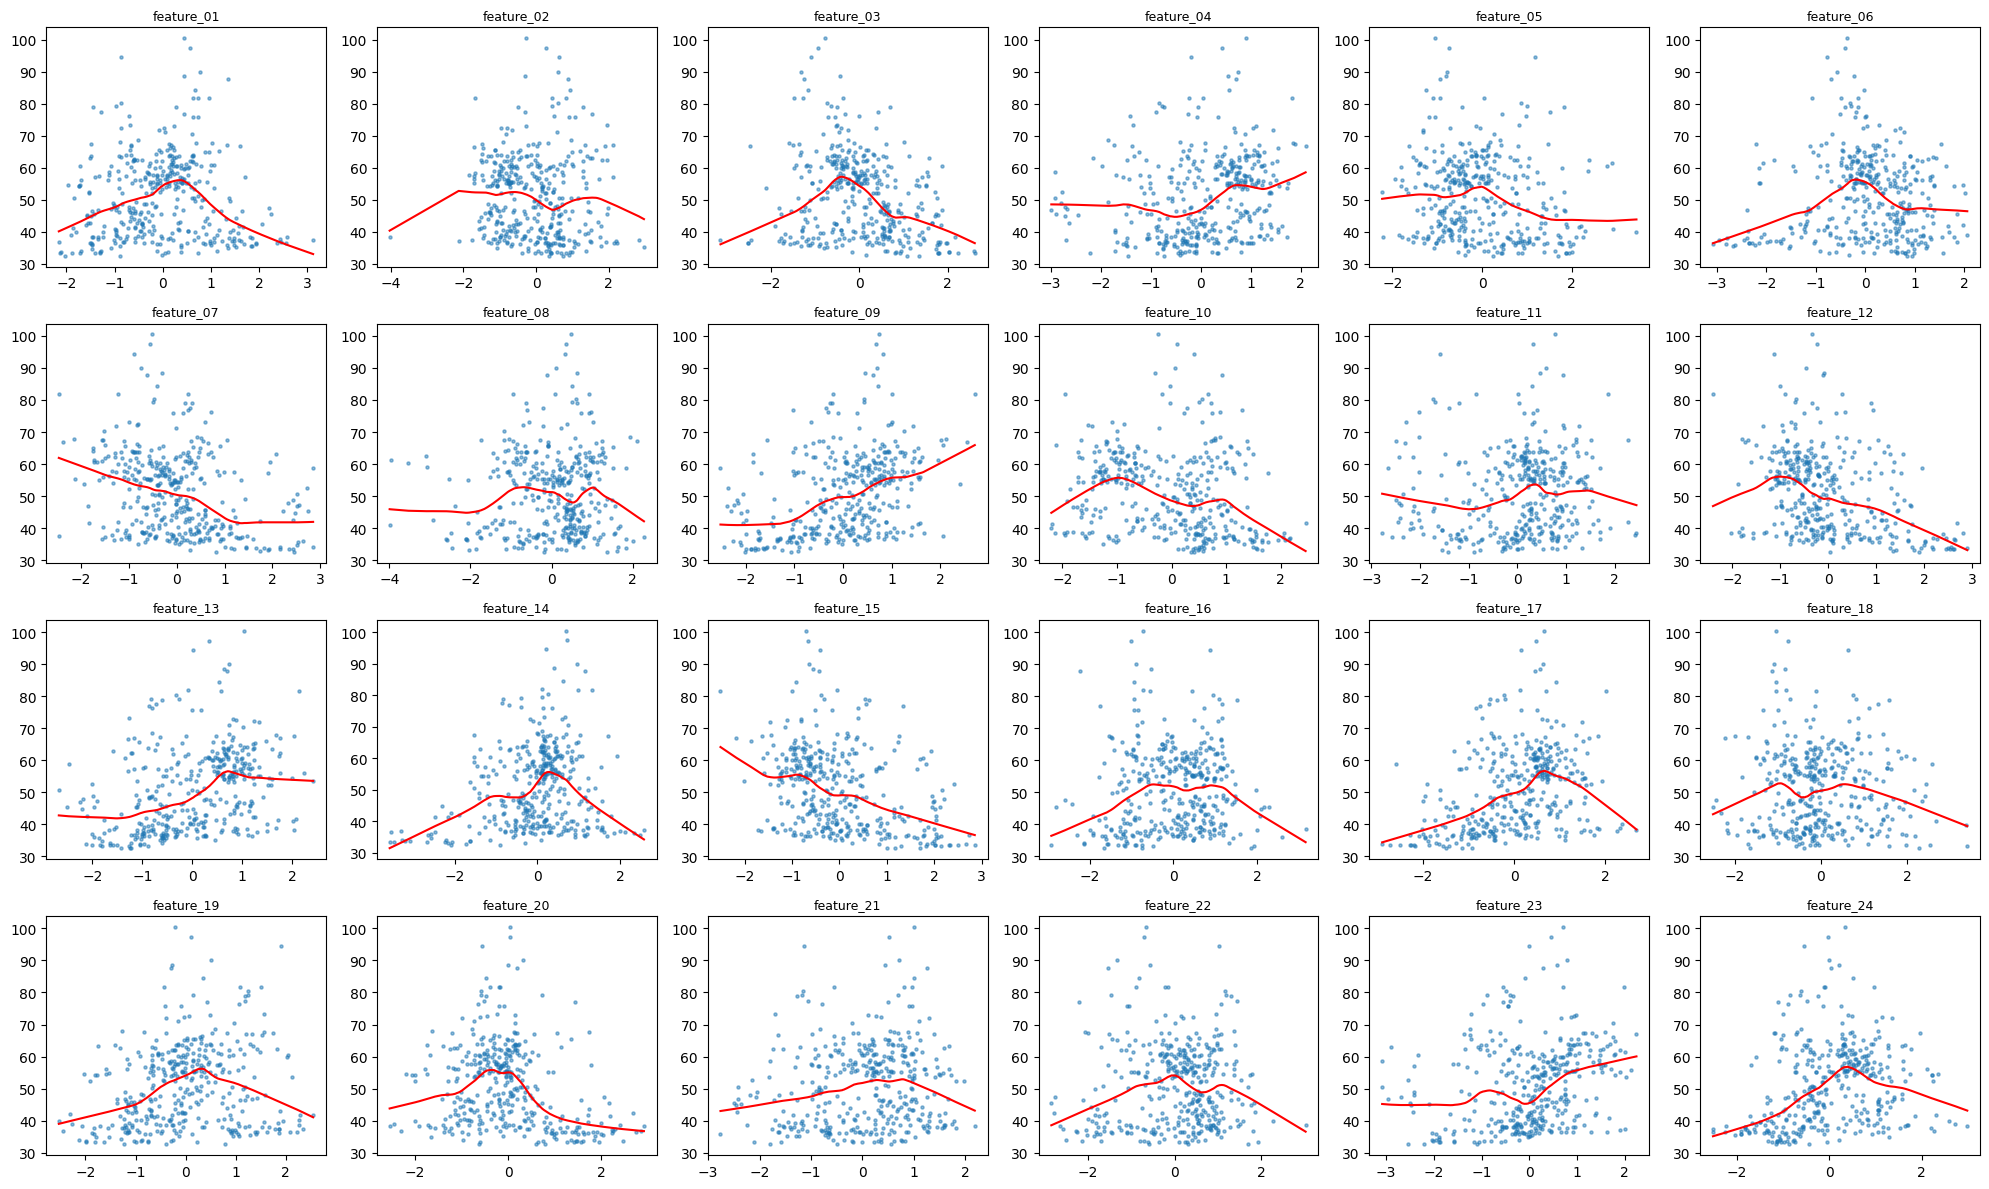

linear (Ridge)     CV RMSE = 10.733
additive splines   CV RMSE = 9.360


In [10]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12))
for a, c in zip(axes.ravel(), FEATURES):
    a.scatter(train[c], y, s=5, alpha=0.5)
    lw = lowess(y, train[c], frac=0.4)
    a.plot(lw[:, 0], lw[:, 1], c='r')
    a.set_title(c, fontsize=9)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'feature_vs_target.png')
plt.show()

cv10 = KFold(10, shuffle=True, random_state=CFG.SEED)
shape_models = {
    'linear (Ridge)'   : make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 30))),
    'additive splines' : make_pipeline(SplineTransformer(n_knots=5), StandardScaler(),
                                       RidgeCV(np.logspace(-2, 4, 30))),
}
for name, m in shape_models.items():
    p = cross_val_predict(m, X, y, cv=cv10)
    print(f'{name:18s} CV RMSE = {np.sqrt(np.mean((y - p) ** 2)):.3f}')

#### Insights

> Many features show an inverted-U shape, where the score peaks when the feature is near zero and falls on both sides (for example `feature_01`, `feature_06`, `feature_14`, `feature_20`). Linear correlation misses this completely, which is why `feature_01` and `feature_06` look useless by Pearson correlation yet gain about 0.12 R2 with a spline.

> Additive splines cut the CV RMSE from about 10.7 to 9.4. A linear model is therefore not enough, and the final models must be able to represent curved and interacting effects.

## Train-Test Shift

Per-feature Kolmogorov-Smirnov tests and an adversarial classifier check whether the test rows come from the same distribution as the training rows.

In [11]:
ks = pd.DataFrame(
    [(c, *stats.ks_2samp(train[c], test[c])) for c in FEATURES],
    columns=['feature', 'KS', 'p'],
).set_index('feature')
print('features with KS p < 0.05:', (ks.p < 0.05).sum(), 'of 24')

is_test = np.r_[np.zeros(len(X)), np.ones(len(X_te))]
skf = StratifiedKFold(5, shuffle=True, random_state=CFG.SEED)
for name, clf in [('logistic', LogisticRegression(max_iter=2000)),
                  ('random forest', RandomForestClassifier(500, min_samples_leaf=3,
                                                           random_state=CFG.SEED, n_jobs=-1))]:
    p = cross_val_predict(clf, X_all, is_test, cv=skf, method='predict_proba')[:, 1]
    print(f'adversarial AUC ({name}): {roc_auc_score(is_test, p):.3f}')

features with KS p < 0.05: 9 of 24
adversarial AUC (logistic): 0.594
adversarial AUC (random forest): 0.534


#### Insights

> Nine of the 24 features have KS p-values below 0.05, but the mean shifts are small (at most about 0.3 standard deviations) and move together along one direction. The adversarial AUC stays close to 0.5 to 0.6, so the test set is only mildly different from the training set.

> No row is removed or reweighted because of the shift. With 96 test rows a mild shift is expected from sampling alone, and reweighting 382 rows would add more variance than it removes.

## Neighbourhood Structure and Validation Design

If the same entity appeared several times with small perturbations, random K-fold would place near-twins in both the training and validation folds and report an optimistic score. The nearest-neighbour distances of training rows and of test rows are compared to decide the split.

train -> train 1-NN distance percentiles: [0.38 0.77 1.15 1.67 2.93]
test  -> train 1-NN distance percentiles: [0.35 0.86 1.24 1.9  3.1 ]
1-NN leave-one-out RMSE: 10.117
radius 0.5: 351 similarity groups, largest group = 6 rows
radius 1.0: 255 similarity groups, largest group = 41 rows
radius 1.5: 141 similarity groups, largest group = 139 rows


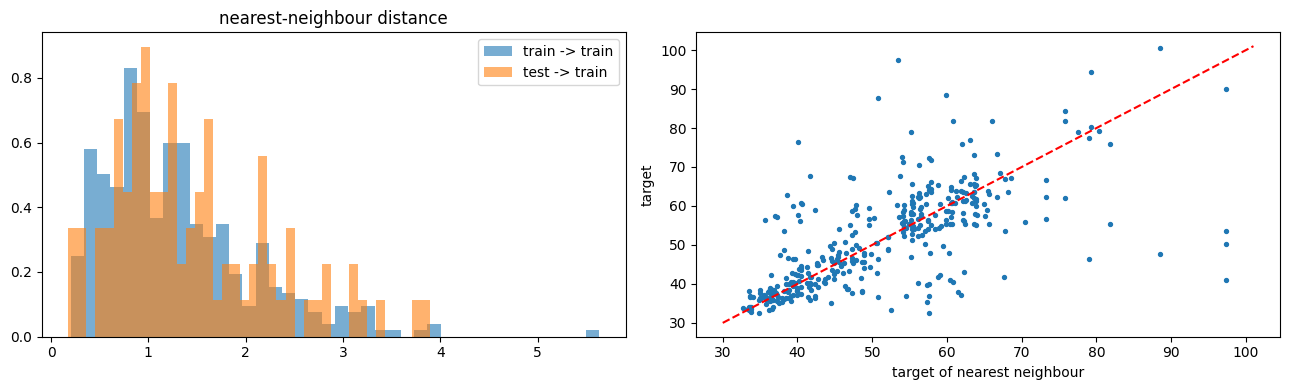

In [12]:
Z_tr, Z_te = Z_all[:len(X)], Z_all[len(X):]
nn = NearestNeighbors(n_neighbors=2).fit(Z_tr)
d_trtr, i_trtr = nn.kneighbors(Z_tr)
d_tetr = nn.kneighbors(Z_te, n_neighbors=1)[0][:, 0]
d_trtr, i_trtr = d_trtr[:, 1], i_trtr[:, 1]

q = [5, 25, 50, 75, 95]
print('train -> train 1-NN distance percentiles:', np.percentile(d_trtr, q).round(2))
print('test  -> train 1-NN distance percentiles:', np.percentile(d_tetr, q).round(2))
print(f'1-NN leave-one-out RMSE: {np.sqrt(np.mean((y - y[i_trtr]) ** 2)):.3f}')

for r in [0.5, 1.0, 1.5]:
    n_grp, lab = connected_components(
        NearestNeighbors(radius=r).fit(Z_tr).radius_neighbors_graph(Z_tr), directed=False)
    print(f'radius {r}: {n_grp} similarity groups, largest group = {np.bincount(lab).max()} rows')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(d_trtr, bins=40, alpha=0.6, density=True, label='train -> train')
ax[0].hist(d_tetr, bins=40, alpha=0.6, density=True, label='test -> train')
ax[0].set_title('nearest-neighbour distance')
ax[0].legend()
ax[1].scatter(y[i_trtr], y, s=8)
ax[1].plot([30, 101], [30, 101], 'r--')
ax[1].set_xlabel('target of nearest neighbour')
ax[1].set_ylabel('target')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'neighbours.png')
plt.show()

#### Insights

> Test rows sit at the same distance from the training set as training rows sit from each other, so random K-fold reproduces the train-to-test situation faithfully. Only 48 training rows have a neighbour within radius 0.5, so near-twin leakage is limited. Section 5 still reports a similarity-grouped K-fold score as a pessimistic cross-check.

> The nearest neighbour's target is already a decent predictor (1-NN RMSE about 10.1), and the agreement is tight in the lower mode but loose for high scores. Local, similarity-based models should therefore do well, while the high tail will remain the hardest region.

---

# Preprocessing Verification <a name="4"></a>

---

The EDA suggests several preprocessing ideas that are sound in theory. Each one is applied, inspected and scored with the same repeated 5-fold split and three different model families, because a transform that is correct on paper can still damage the evaluation score.

## Validation Utilities

One fixed list of folds is shared by every experiment in the notebook so that all scores are directly comparable. The target transform is applied inside each fold, and unsupervised feature transforms are fitted on the features of train and test together without the target.

In [13]:
FOLDS = list(RepeatedKFold(n_splits=CFG.N_SPLITS, n_repeats=CFG.N_REPEATS,
                           random_state=CFG.SEED).split(X))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def log_target(model):
    return TransformedTargetRegressor(
        model,
        func=lambda t: np.log(t - CFG.LOG_SHIFT),
        inverse_func=lambda p: np.exp(p) + CFG.LOG_SHIFT,
        check_inverse=False,
    )


def z_target(model):
    return TransformedTargetRegressor(model, transformer=StandardScaler())


def run_cv(make_model, Xm, Xm_te=None):
    oof = np.zeros((CFG.N_REPEATS, len(y)))
    for i, (tri, vai) in enumerate(FOLDS):
        oof[i // CFG.N_SPLITS, vai] = make_model().fit(Xm[tri], y[tri]).predict(Xm[vai])
    score = np.mean([rmse(y, o) for o in oof])
    pred_te = None if Xm_te is None else make_model().fit(Xm, y).predict(Xm_te)
    return score, oof.mean(0), pred_te


def pca_view(k):
    pca = PCA(k, random_state=CFG.SEED).fit(Z_all)
    P = pca.transform(Z_all)
    P = P / P.std(0)
    return P[:len(X)], P[len(X):]


print(f'{len(FOLDS)} folds, validation size {len(FOLDS[0][1])}')

15 folds, validation size 77


## Feature Representation

Four ideas follow from Section 3. Quantile normalisation could help distance-based models, PCA denoising could remove the controlled perturbation, and ICA could undo the private linear projection and recover the original indicators. Each representation is scored with SVR, kNN and ExtraTrees.

In [14]:
svr_probe = lambda: z_target(make_pipeline(StandardScaler(), SVR(C=3, gamma='scale', epsilon=0.1)))
knn_probe = lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(7, weights='distance'))
et_probe  = lambda: ExtraTreesRegressor(400, min_samples_leaf=2, max_features=0.5,
                                        random_state=CFG.SEED, n_jobs=-1)
PROBES = {'SVR': svr_probe, 'kNN': knn_probe, 'ExtraTrees': et_probe}

reps = {'raw': X}
reps['quantile-normal'] = (pd.DataFrame(X_all).rank().values[:len(X)] - 0.5) / len(X_all)
reps['quantile-normal'] = stats.norm.ppf(reps['quantile-normal'])
for k in [4, 8, 12]:
    pca = PCA(k, random_state=CFG.SEED).fit(Z_all)
    reps[f'pca-denoise k={k}'] = pca.inverse_transform(pca.transform(Z_all[:len(X)]))
    reps[f'pca-scores k={k}'] = pca_view(k)[0]
ica_models = {}
for k in [6, 10]:
    ica_models[k] = FastICA(k, whiten='unit-variance', max_iter=5000, random_state=CFG.SEED).fit(Z_all)
    reps[f'ica k={k}'] = ica_models[k].transform(Z_all[:len(X)])

rep_scores = pd.DataFrame({
    name: {p: run_cv(make, Xm)[0] for p, make in PROBES.items()} for name, Xm in reps.items()
}).T
rep_scores['mean'] = rep_scores.mean(axis=1)
print(rep_scores.sort_values('mean').round(3).to_string())

                     SVR     kNN  ExtraTrees    mean
pca-scores k=12    8.232   9.092       8.952   8.759
ica k=10           8.383   8.867       9.492   8.914
pca-scores k=8     8.612   9.105       9.115   8.944
raw                8.640   9.425       8.894   8.986
pca-denoise k=12   8.717   9.396       8.947   9.020
quantile-normal    8.701   9.457       9.004   9.054
ica k=6            8.975   9.122       9.445   9.181
pca-denoise k=8    9.045   9.514       9.023   9.194
pca-scores k=4    10.385  10.050       9.876  10.104
pca-denoise k=4   10.649  10.065       9.636  10.117


The ICA sources are inspected directly. If ICA had recovered the original indicators, the sources would look like rank-normalised, bounded variables, which means flat distributions with negative excess kurtosis, and they would relate to the target more cleanly than the raw features do.

excess kurtosis per source (uniform = -1.2): [ 4.55  1.69 -0.96  5.33  7.25  1.27  9.35  2.2   2.26  2.95]
max |spearman| with target, raw features: 0.391 | ICA sources: 0.259


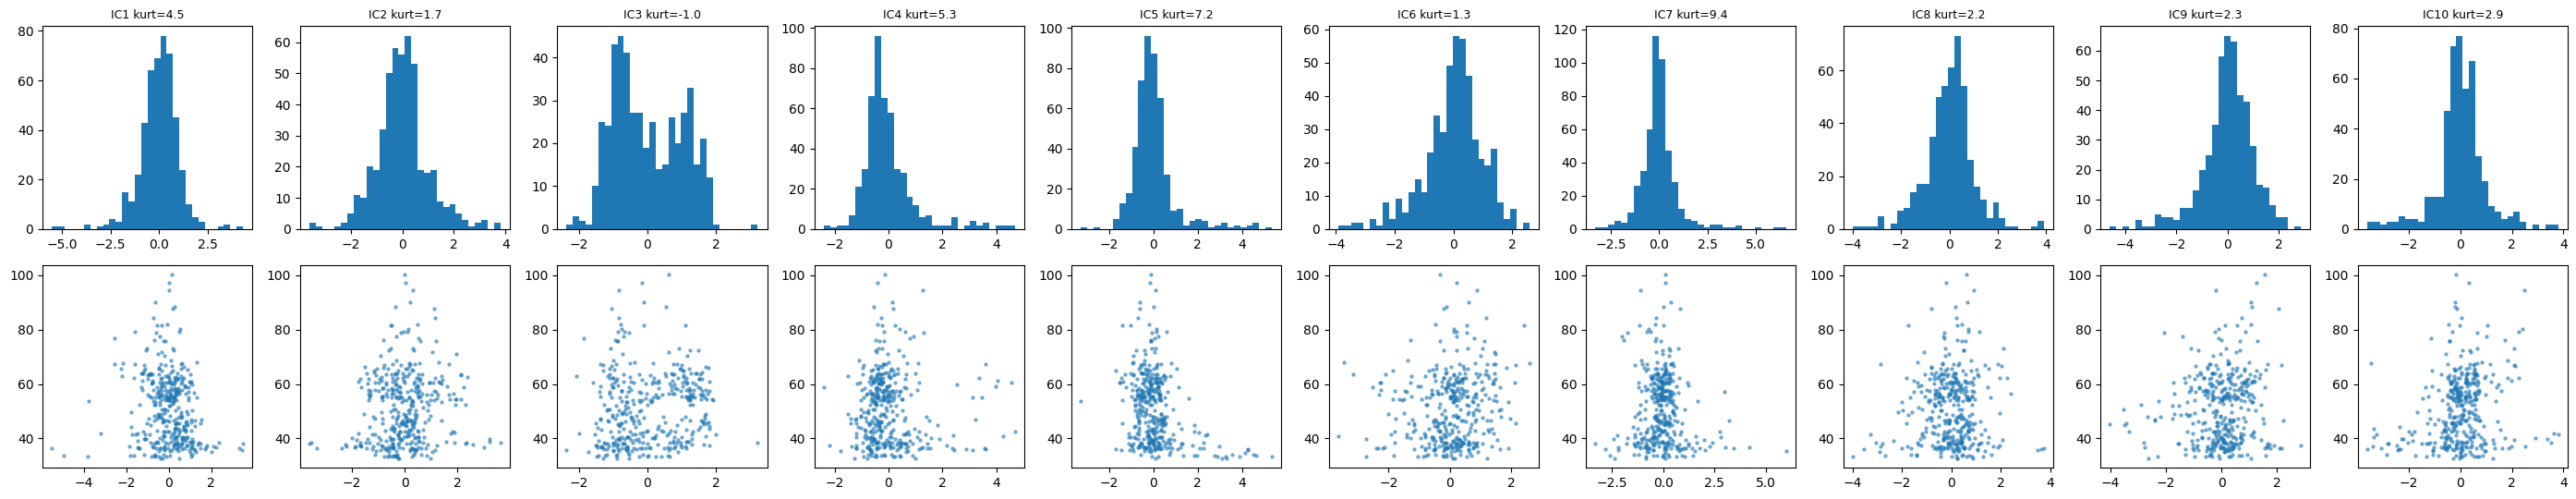

In [15]:
S_all = ica_models[10].transform(Z_all)
kurt = stats.kurtosis(S_all, axis=0)
rho = [stats.spearmanr(S_all[:len(X), j], y)[0] for j in range(10)]
print('excess kurtosis per source (uniform = -1.2):', np.round(kurt, 2))
print('max |spearman| with target, raw features:', round(t_corr.abs().max(), 3),
      '| ICA sources:', round(np.max(np.abs(rho)), 3))

fig, axes = plt.subplots(2, 10, figsize=(28, 5.5))
for j in range(10):
    axes[0, j].hist(S_all[:, j], bins=30)
    axes[0, j].set_title(f'IC{j + 1} kurt={kurt[j]:.1f}', fontsize=9)
    axes[1, j].scatter(S_all[:len(X), j], y, s=5, alpha=0.5)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'ica_sources.png')
plt.show()

#### Insights

> Quantile normalisation and PCA denoising do not help. Keeping only four components, as the noise-edge analysis would suggest, is clearly harmful (RMSE above 10), which confirms that part of the target signal lives in low-variance directions. PCA scores with about 12 components are the best view for SVR, while ExtraTrees prefers the raw features and kNN is roughly indifferent.

> ICA fails its own sanity check. The recovered sources are heavy-tailed (excess kurtosis up to about 9) instead of flat, and they correlate with the target less than the raw features do. ICA is latching onto outlier directions rather than undoing the projection, because the bounded transformation and the added perturbation break its independence assumption. It is dropped.

## Target Transform

The shifted log target looked more regular in Section 3. The first attempt at this experiment used an SVR with a fixed `epsilon=1.0`, and the log target made RMSE jump by about four points. The cause is scale, since `epsilon` and `C` are expressed in target units and an epsilon of 1.0 is wider than the whole spread of the log target. The fix standardises the target inside the model before the transform is judged.

In [16]:
Xp12 = pca_view(CFG.PCA_DIM)[0]
svr_fixed_eps = lambda: make_pipeline(StandardScaler(), SVR(C=30, gamma='scale', epsilon=1.0))
rows = {
    'SVR eps=1.0, y'                     : run_cv(svr_fixed_eps, Xp12)[0],
    'SVR eps=1.0, log y   (broken)'      : run_cv(lambda: log_target(svr_fixed_eps()), Xp12)[0],
    'SVR z-scaled, y'                    : run_cv(svr_probe, Xp12)[0],
    'SVR z-scaled, log y  (fixed)'       : run_cv(lambda: log_target(svr_probe()), Xp12)[0],
    'kNN, y'                             : run_cv(knn_probe, Xp12)[0],
    'kNN, log y'                         : run_cv(lambda: log_target(knn_probe()), Xp12)[0],
    'ExtraTrees, y'                      : run_cv(et_probe, X)[0],
    'ExtraTrees, log y'                  : run_cv(lambda: log_target(et_probe()), X)[0],
}
print(pd.Series(rows).round(3).to_string())

SVR eps=1.0, y                    8.259
SVR eps=1.0, log y   (broken)    12.689
SVR z-scaled, y                   8.232
SVR z-scaled, log y  (fixed)      8.160
kNN, y                            9.092
kNN, log y                        8.788
ExtraTrees, y                     8.894
ExtraTrees, log y                 9.220


#### Insights

> The log target was never the problem. Once the SVR target is standardised, the log transform no longer breaks the SVR and gives it a small gain, and it lowers the kNN error by about 0.3, because it spreads the crowded lower mode and shrinks the influence of the few extreme scores on distance-based fits.

> The same transform hurts ExtraTrees. Trees split on target averages, and averaging in log space and then exponentiating biases predictions downward for the high tail, which RMSE punishes. The target transform is therefore chosen per model family and never applied globally.

## PCA Dimension Robustness

The best PCA dimension for SVR is 12, but a sweep shows the score is bumpy across dimensions (for example 8.13 at 12 components and 8.62 at 14). Picking a single sharp optimum on 382 rows risks fitting the validation noise, so an average of SVRs over several dimensions is compared with the single best dimension under three different fold seeds.

In [17]:
PCA_DIMS = [10, 12, 14, 16, 20]
views = {k: pca_view(k) for k in PCA_DIMS}


def svr_multi_pca_cv(dims, seed):
    err = []
    for tri, vai in RepeatedKFold(n_splits=5, n_repeats=3, random_state=seed).split(X):
        preds = []
        for k in dims:
            m = log_target(z_target(SVR(C=3, gamma=1 / k, epsilon=0.05)))
            preds.append(m.fit(views[k][0][tri], y[tri]).predict(views[k][0][vai]))
        err.append(np.mean((y[vai] - np.mean(preds, 0)) ** 2))
    return np.sqrt(np.mean(err))


robust = pd.DataFrame({
    seed: {'single k=12': svr_multi_pca_cv([12], seed),
           'average k=10..20': svr_multi_pca_cv(PCA_DIMS, seed)}
    for seed in [42, 7, 123]
})
print(robust.round(4).to_string())

                     42      7       123
single k=12       8.1336  8.2057  7.9562
average k=10..20  8.1136  8.1339  7.9435


#### Insights

> Averaging SVRs over five PCA dimensions matches or beats the single best dimension under every fold seed. It removes the need to select one sharp hyperparameter on a small dataset, so the multi-dimension SVR is used as the kernel model in Section 5.

---

# Modelling <a name="5"></a>

---

Five model families are trained on the shared folds. Ridge is the linear baseline, CatBoost represents gradient boosting, the multi-dimension SVR is the verified kernel model, and TabPFN v2 and TabICLv2 are pretrained tabular foundation models. The two foundation models are placed on separate T4 GPUs.

## Pretrained Foundation Models

With 382 rows, a model trained from scratch has very little data to learn a prior from. Tabular foundation models solve this by pretraining a transformer on millions of synthetic datasets and then predicting new rows through in-context learning, where the training set is passed as context and no weights are updated on the competition data. TabICLv2 (open weights, Hugging Face `jingang/TabICL`) is reported to outperform RealTabPFN-2.5 on the TabArena and TALENT benchmarks, and TabPFN v2 (Hugging Face `Prior-Labs/TabPFN-v2-reg`) is its most widely used predecessor. Both are used only as learning algorithms on the official data, which the competition rules allow.

In [18]:
class MultiPCASVR:
    def __init__(self, dims=PCA_DIMS):
        self.dims = dims
        self.pcas = {k: PCA(k, random_state=CFG.SEED).fit(Z_all) for k in dims}
        self.sds = {k: self.pcas[k].transform(Z_all).std(0) for k in dims}

    def _view(self, k, A):
        return self.pcas[k].transform(sc_all.transform(A)) / self.sds[k]

    def fit(self, A, t):
        self.models = {
            k: log_target(z_target(SVR(C=3, gamma=1 / k, epsilon=0.05))).fit(self._view(k, A), t)
            for k in self.dims
        }
        return self

    def predict(self, A):
        return np.mean([self.models[k].predict(self._view(k, A)) for k in self.dims], 0)


GPU_A = CFG.DEVICES[0]
GPU_B = CFG.DEVICES[-1]

MODELS = {
    'Ridge'       : lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 30))),
    'CatBoost'    : lambda: CatBoostRegressor(iterations=1500, learning_rate=0.02, depth=5,
                                              l2_leaf_reg=5, verbose=0, random_seed=CFG.SEED,
                                              allow_writing_files=False),
    'SVR-multiPCA': MultiPCASVR,
    'TabPFNv2'    : lambda: TabPFNRegressor.create_default_for_version(
                        ModelVersion.V2, device=GPU_B, n_estimators=16, random_state=CFG.SEED),
    'TabICLv2'    : lambda: TabICLRegressor(device=GPU_A, random_state=CFG.SEED),
}
print('TabICLv2 on', GPU_A, '| TabPFNv2 on', GPU_B)

TabICLv2 on cuda:0 | TabPFNv2 on cuda:1


## Cross-Validation

Each model is scored on the 15 shared folds. The reported RMSE is the mean over the three repeats, the out-of-fold predictions are averaged over repeats for the blend, and each model is refitted on all 382 rows to predict the test set.

Ridge         RMSE=10.7674  (0s)
CatBoost      RMSE=8.8969  (43s)
SVR-multiPCA  RMSE=8.1136  (1s)


tabpfn-v2-regressor.ckpt:   0%|          | 0.00/44.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

TabPFNv2      RMSE=7.9165  (26s)
Checkpoint 'tabicl-regressor-v2-20260212.ckpt' not cached.



tabicl-regressor-v2-20260212.ckpt:   0%|          | 0.00/114M [00:00<?, ?B/s]

TabICLv2      RMSE=7.6337  (14s)

                 RMSE  MAE (bagged OOF)  seconds
model                                           
TabICLv2       7.6337            5.0578  13.7393
TabPFNv2       7.9165            5.3523  25.8035
SVR-multiPCA   8.1136            5.4958   1.0755
CatBoost       8.8969            6.2403  42.6713
Ridge         10.7674            8.0303   0.0793


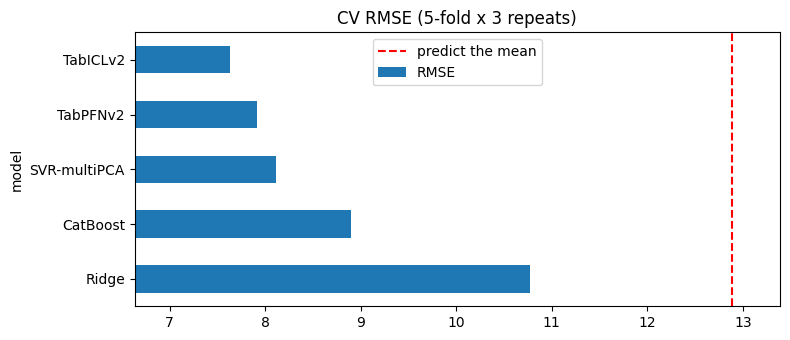

In [19]:
OOF, TEST, rows = {}, {}, []
for name, make in MODELS.items():
    t0 = time.time()
    score, OOF[name], TEST[name] = run_cv(make, X, X_te)
    rows.append((name, score, np.mean(np.abs(y - OOF[name])), time.time() - t0))
    print(f'{name:13s} RMSE={score:.4f}  ({rows[-1][3]:.0f}s)')

cv_table = pd.DataFrame(rows, columns=['model', 'RMSE', 'MAE (bagged OOF)', 'seconds']).set_index('model')
cv_table = cv_table.sort_values('RMSE')
print()
print(cv_table.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
cv_table['RMSE'].plot.barh(ax=ax)
ax.axvline(y.std(), c='r', ls='--', label='predict the mean')
ax.set_xlim(cv_table['RMSE'].min() - 1, y.std() + 0.5)
ax.invert_yaxis()
ax.legend()
ax.set_title('CV RMSE (5-fold x 3 repeats)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'cv_leaderboard.png')
plt.show()

## Pessimistic Cross-Check with Similarity Groups

Rows that lie within radius 1.0 of each other in standardised feature space are chained into groups and kept in the same fold. This is harsher than the real train-to-test situation, so the scores will rise, but the ranking of the models should not change if the choice is robust.

In [20]:
_, sim_groups = connected_components(
    NearestNeighbors(radius=1.0).fit(Z_tr).radius_neighbors_graph(Z_tr), directed=False)
for name in ['Ridge', 'CatBoost', 'SVR-multiPCA', 'TabICLv2']:
    p = np.zeros(len(y))
    for tri, vai in GroupKFold(5).split(X, y, sim_groups):
        p[vai] = MODELS[name]().fit(X[tri], y[tri]).predict(X[vai])
    print(f'{name:13s} GroupKFold RMSE={rmse(y, p):.4f}  |  random KFold RMSE={cv_table.loc[name, "RMSE"]:.4f}')

Ridge         GroupKFold RMSE=11.2394  |  random KFold RMSE=10.7674
CatBoost      GroupKFold RMSE=9.6010  |  random KFold RMSE=8.8969
SVR-multiPCA  GroupKFold RMSE=8.6166  |  random KFold RMSE=8.1136
TabICLv2      GroupKFold RMSE=7.9297  |  random KFold RMSE=7.6337


#### Insights

> The pretrained foundation models lead without any tuning. TabICLv2 reaches a CV RMSE of about 7.6 and TabPFN v2 about 7.9, ahead of the tuned SVR (about 8.1), CatBoost (about 8.9) and the linear baseline (about 10.8). In local experiments, increasing TabICLv2 to 32 estimators or appending PCA features did not improve it, so the default configuration is kept.

> Under similarity-grouped folds every model gets worse by about 0.3 to 0.8 points, but the order is unchanged and TabICLv2 degrades the least. The model choice is therefore not an artefact of near-duplicate rows leaking across folds.

---

# Ensemble and Error Analysis <a name="6"></a>

---

A blend helps only when models make different mistakes. The residual correlation matrix shows which models are complementary, and the blend weights are then estimated with non-negative least squares on the out-of-fold predictions.

## Residual Correlation

Residuals are computed from the out-of-fold predictions of each model. A correlation near 1 means two models fail on the same rows and blending them adds little.

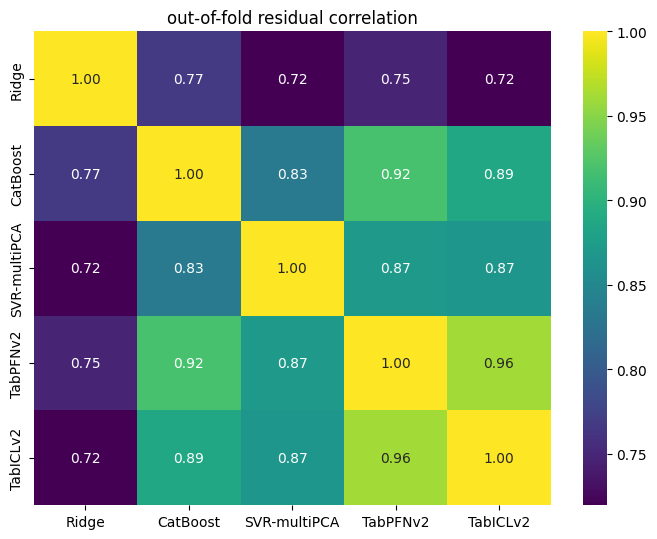

In [21]:
names = list(MODELS)
resid = pd.DataFrame({n: y - OOF[n] for n in names})
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(resid.corr(), annot=True, fmt='.2f', cmap='viridis', ax=ax)
ax.set_title('out-of-fold residual correlation')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'residual_corr.png')
plt.show()

## Blend Weights

Non-negative least squares finds the weights, which are then normalised to sum to one. To avoid judging the blend on the same rows that chose its weights, a nested 10-fold loop fits the weights on nine tenths of the out-of-fold rows and scores the remaining tenth.

In [22]:
def nnls_weights(P, t):
    w, _ = nnls(P, t)
    return w / w.sum()


P_oof  = np.column_stack([OOF[n] for n in names])
P_test = np.column_stack([TEST[n] for n in names])

nested = np.zeros(len(y))
for a, b in KFold(10, shuffle=True, random_state=CFG.SEED).split(P_oof):
    nested[b] = P_oof[b] @ nnls_weights(P_oof[a], y[a])

weights = pd.Series(nnls_weights(P_oof, y), index=names)
blend_oof = P_oof @ weights.values
print(weights.round(3).to_string())
print(f'\nbest single model (bagged OOF) RMSE : {min(rmse(y, OOF[n]) for n in names):.4f}')
print(f'blend, nested estimate RMSE        : {rmse(y, nested):.4f}')
print(f'blend, in-sample RMSE              : {rmse(y, blend_oof):.4f}')

Ridge           0.000
CatBoost        0.000
SVR-multiPCA    0.281
TabPFNv2        0.000
TabICLv2        0.719

best single model (bagged OOF) RMSE : 7.4476
blend, nested estimate RMSE        : 7.4098
blend, in-sample RMSE              : 7.3717


#### Insights

> The blend keeps TabICLv2 (weight about 0.7) and the multi-dimension SVR (about 0.3) and gives zero weight to the others. TabPFN v2 is accurate on its own, but its residuals correlate at about 0.96 with TabICLv2, so it adds no new information. The SVR is weaker alone but works on a PCA view with a log target, which makes its mistakes different enough to be useful.

> The nested estimate stays close to the in-sample value, so the two weights are not overfitted. In local runs the nested blend RMSE was stable at about 7.40 to 7.42 across three different outer seeds.

## Where the Blend Fails

The out-of-fold residuals are grouped by target range to find which rows drive the RMSE. A simple linear stretch of the blend is also tested, since models trained with squared error tend to pull extreme predictions toward the mean.

             n    bias    rmse  share_of_SSE
bin                                         
(30, 40]   100  -3.730   5.620         0.152
(40, 50]    90  -2.153   5.373         0.125
(50, 60]    95  -0.296   5.881         0.158
(60, 70]    71   3.289   6.685         0.153
(70, 80]    15  13.364  14.572         0.153
(80, 101]   11  20.417  22.072         0.258

slope of y on nested blend = 1.089
nested RMSE without stretch = 7.4098 | with stretch = 7.4143


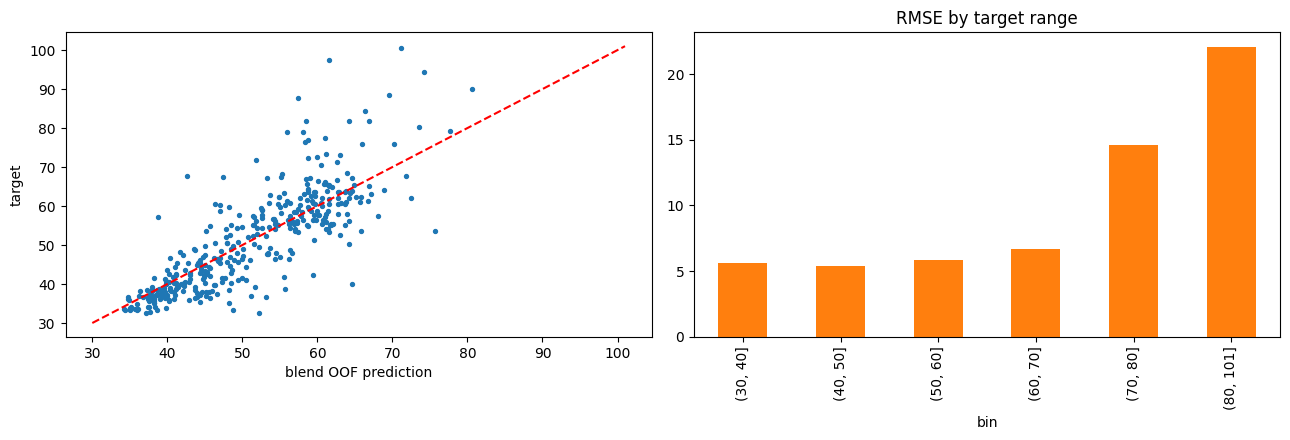

In [23]:
err = pd.DataFrame({'y': y, 'res': y - blend_oof})
err['bin'] = pd.cut(err.y, [30, 40, 50, 60, 70, 80, 101])
by_bin = err.groupby('bin', observed=True).agg(
    n=('y', 'size'), bias=('res', 'mean'), rmse=('res', lambda r: np.sqrt(np.mean(r ** 2))))
by_bin['share_of_SSE'] = err.groupby('bin', observed=True).res.apply(lambda r: (r ** 2).sum()) / (err.res ** 2).sum()
print(by_bin.round(3).to_string())

slope, intercept = np.polyfit(nested, y, 1)
stretched = np.zeros(len(y))
for a, b in KFold(10, shuffle=True, random_state=CFG.SEED).split(P_oof):
    w_a = nnls_weights(P_oof[a], y[a])
    stretched[b] = np.polyval(np.polyfit(P_oof[a] @ w_a, y[a], 1), P_oof[b] @ w_a)
print(f'\nslope of y on nested blend = {slope:.3f}')
print(f'nested RMSE without stretch = {rmse(y, nested):.4f} | with stretch = {rmse(y, stretched):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(blend_oof, y, s=8)
ax[0].plot([30, 101], [30, 101], 'r--')
ax[0].set_xlabel('blend OOF prediction')
ax[0].set_ylabel('target')
by_bin['rmse'].plot.bar(ax=ax[1], color='tab:orange')
ax[1].set_title('RMSE by target range')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'error_analysis.png')
plt.show()

#### Insights

> The error is concentrated in the right tail. The 26 training rows with a score above 70 (about 7% of the data) carry roughly 40% of the squared error, and the blend under-predicts them by 13 to 20 points on average. Below 70 the RMSE is only about 5 to 7.

> The slope of the target on the blend is slightly above one, which confirms mild shrinkage toward the mean, but correcting it with a linear stretch changes the nested RMSE by less than 0.01 and in some runs makes it slightly worse. The high scores are not predictable from the features with this little data, so the stretch is not applied. Forcing predictions outward would add variance on the other 93% of rows for a gain that does not survive validation.

## How Much to Trust the Public Leaderboard

The public leaderboard uses about 30% of the 96 test rows, roughly 29 records. Resampling 29 out-of-fold residuals many times shows how much the public score can move by chance alone.

OOF RMSE 7.372
public (29 rows)  90% range: 4.74 to 9.89
private (67 rows) 90% range: 5.68 to 8.96


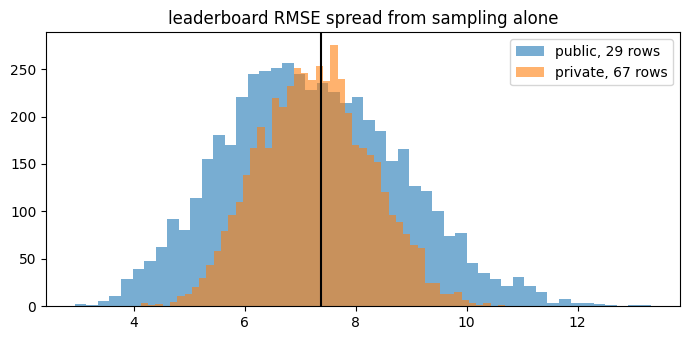

In [24]:
rng = np.random.default_rng(CFG.SEED)
res_blend = y - blend_oof
pub = [np.sqrt(np.mean(rng.choice(res_blend, 29, replace=False) ** 2)) for _ in range(5000)]
prv = [np.sqrt(np.mean(rng.choice(res_blend, 67, replace=False) ** 2)) for _ in range(5000)]
print(f'OOF RMSE {rmse(y, blend_oof):.3f}')
print(f'public (29 rows)  90% range: {np.percentile(pub, 5):.2f} to {np.percentile(pub, 95):.2f}')
print(f'private (67 rows) 90% range: {np.percentile(prv, 5):.2f} to {np.percentile(prv, 95):.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(pub, bins=50, alpha=0.6, label='public, 29 rows')
ax.hist(prv, bins=50, alpha=0.6, label='private, 67 rows')
ax.axvline(rmse(y, blend_oof), c='k')
ax.legend()
ax.set_title('leaderboard RMSE spread from sampling alone')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'lb_noise.png')
plt.show()

#### Insights

> The same model can score anywhere from about 4.7 to 9.9 on the public leaderboard purely from which 29 rows are public, because a single tail record in or out of the public split moves the score by more than a point. The spread on the private split is about half as wide.

> Model selection is therefore done by cross-validation on 382 rows, and the public leaderboard is used only as a sanity check that the submission file is valid and in the expected range. Tuning toward the public score would fit the noise of 29 rows.

---

# Submission <a name="7"></a>

---

The blend weights from Section 6 are applied to the test predictions of the models refitted on all training rows. The file follows `submission_template.csv` exactly, with one prediction per `record_id` and no missing values.

In [25]:
pred = P_test @ weights.values
submission = template[['record_id']].merge(
    pd.DataFrame({'record_id': test['record_id'], 'prediction': pred}), on='record_id', how='left')

assert list(submission.columns) == ['record_id', 'prediction']
assert len(submission) == len(template) == len(test)
assert submission['record_id'].is_unique
assert set(submission['record_id']) == set(test['record_id'])
assert submission['prediction'].notna().all()

submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(submission.head())
print(f'\ntest prediction mean {pred.mean():.2f}  range {pred.min():.2f} to {pred.max():.2f}')
print(f'train OOF blend mean {blend_oof.mean():.2f}  range {blend_oof.min():.2f} to {blend_oof.max():.2f}')

  record_id  prediction
0     D0263   85.160199
1     D0280   76.240440
2     D0206   41.623666
3     D0133   38.412466
4     D0352   61.711117

test prediction mean 50.13  range 34.69 to 85.16
train OOF blend mean 51.04  range 34.22 to 80.54


#### Insights

> The test predictions have a mean and range similar to the out-of-fold predictions on the training set, which is consistent with the mild shift measured in Section 3. The file `submission.csv` in the output directory is the final submission.